# 01 — Load PAMTRA simulations and build synthetic measurements

Converts the PAMTRA forward simulation into the same structure the real-data
pipeline uses, so notebooks 02-04 can run with minimal changes.

Key point: `thickness` becomes `Time` so that `retrieve_lwc_zhu` works unchanged.
Each "time step" is an independent cloud scene, NOT a time series.
Nothing in this pipeline may average along that axis.

In [10]:
from pathlib import Path

import numpy as np
import xarray as xr

RAW_PATH = Path("../data/raw/cmtrace/Pamtra_test_1/pamtra_simulations.nc")
OUT_DIR  = Path("../data/processed/pamtra_test_1")
OUT_DIR.mkdir(parents=True, exist_ok=True)

ds_raw = xr.open_dataset(RAW_PATH)
print(ds_raw)

<xarray.Dataset> Size: 230kB
Dimensions:              (thickness: 54, height: 74, frequency: 2,
                          height_bounds: 75)
Coordinates:
  * thickness            (thickness) float64 432B 22.36 44.72 ... 1.454e+03
  * height               (height) float64 592B 111.8 134.2 ... 1.998e+03
  * frequency            (frequency) float64 16B 35.0 94.0
  * height_bounds        (height_bounds) float64 600B 100.6 123.0 ... 2.011e+03
Data variables:
    lwc                  (thickness, height) float64 32kB ...
    height_bounds_lower  (height) float64 592B ...
    height_bounds_upper  (height) float64 592B ...
    Ze                   (thickness, height, frequency) float64 64kB ...
    att_gas              (thickness, height, frequency) float64 64kB ...
    att_liquid           (thickness, height, frequency) float64 64kB ...
    temp_lev             (height_bounds) float64 600B ...
    relhum_lev           (height_bounds) float64 600B ...
    press_lev            (height_bounds) fl

## Check the attenuation convention

PAMTRA can report attenuation either per layer or cumulated from the ground up.
Cumulative arrays increase monotonically with height; per-layer arrays do not.
This determines how the synthetic measurement is built below, so check it before
going further.

In [11]:
ag = ds_raw["att_gas"].isel(thickness=-1).sel(frequency=94.0).values
al = ds_raw["att_liquid"].isel(thickness=-1).sel(frequency=94.0).values

print("att_gas    first 6:", np.round(ag[:6], 5))
print("att_gas     last 6:", np.round(ag[-6:], 5))
print("monotonic increasing:", bool(np.all(np.diff(ag[np.isfinite(ag)]) >= -1e-12)))
print()
print("att_liquid first 6:", np.round(al[:6], 5))
print("att_liquid  last 6:", np.round(al[-6:], 5))
print("monotonic increasing:", bool(np.all(np.diff(al[np.isfinite(al)]) >= -1e-12)))
print()
print("att_gas units   :", ds_raw["att_gas"].attrs.get("units"))
print("att_liquid units:", ds_raw["att_liquid"].attrs.get("units"))

att_gas    first 6: [0.00071 0.00071 0.00071 0.0007  0.0007  0.0007 ]
att_gas     last 6: [0.00065 0.00064 0.00064 0.00064 0.00063 0.00063]
monotonic increasing: False

att_liquid first 6: [0. 0. 0. 0. 0. 0.]
att_liquid  last 6: [0.11223 0.11423 0.11621 0.11818 0.12014 0.     ]
monotonic increasing: False

att_gas units   : dB
att_liquid units: dB


Set the flag below from what the check printed.

- `True`  -> arrays already accumulate from the ground up, use them directly
- `False` -> arrays are per layer, cumulate them here with `cumsum`

In [12]:
ATT_IS_CUMULATIVE = False   # <-- set from the check above

# One-way attenuation from ground to each gate, per frequency
if ATT_IS_CUMULATIVE:
    att_gas_cum    = ds_raw["att_gas"]
    att_liquid_cum = ds_raw["att_liquid"]
else:
    att_gas_cum    = ds_raw["att_gas"].fillna(0.0).cumsum("height")
    att_liquid_cum = ds_raw["att_liquid"].fillna(0.0).cumsum("height")

# Two-way path-integrated attenuation seen by the radar
att_two_way = 2.0 * (att_gas_cum + att_liquid_cum)

# Synthetic measured reflectivity = true Ze minus what the atmosphere removes
Ze_measured = ds_raw["Ze"] - att_two_way

print("two-way attenuation at cloud top, thickest case:")
for f in [35.0, 94.0]:
    v = att_two_way.isel(thickness=-1).sel(frequency=f).values
    v = v[np.isfinite(v)]
    print(f"  {f:5.1f} GHz: {v[-1]:.3f} dB")

two-way attenuation at cloud top, thickest case:
   35.0 GHz: 1.510 dB
   94.0 GHz: 6.947 dB


## Restructure into the pipeline's dimension names

In [13]:
ds = xr.Dataset()

# thickness -> Time  (so zhu.py runs unchanged), height -> range
Ze_meas = Ze_measured.rename({"thickness": "Time", "height": "range"})
Ze_true = ds_raw["Ze"].rename({"thickness": "Time", "height": "range"})

ds["Ze_Ka"] = Ze_meas.sel(frequency=35.0, drop=True)
ds["Ze_W"]  = Ze_meas.sel(frequency=94.0, drop=True)

# Unattenuated versions, kept for diagnostics only
ds["Ze_Ka_true"] = Ze_true.sel(frequency=35.0, drop=True)
ds["Ze_W_true"]  = Ze_true.sel(frequency=94.0, drop=True)

# PAMTRA's own gas attenuation, converted to a specific attenuation in dB/km.
# alpha in the retrieval is a RATE, not a path integral.
dh_km = np.gradient(ds_raw["height"].values) / 1000.0
dh_da = xr.DataArray(dh_km, dims=["range"], coords={"range": ds_raw["height"].values})

if ATT_IS_CUMULATIVE:
    gas_layer = ds_raw["att_gas"].fillna(0.0).diff("height", label="upper")
    gas_layer = gas_layer.reindex(height=ds_raw["height"], fill_value=np.nan)
    gas_layer = gas_layer.bfill("height")
else:
    gas_layer = ds_raw["att_gas"].fillna(0.0)

alpha_gas = (gas_layer.rename({"thickness": "Time", "height": "range"}) / dh_da)
ds["alpha_Ka_pamtra"] = alpha_gas.sel(frequency=35.0, drop=True)
ds["alpha_W_pamtra"]  = alpha_gas.sel(frequency=94.0, drop=True)

# Truth
ds["LWC_true"] = (ds_raw["lwc"] * 1000.0).rename({"thickness": "Time", "height": "range"})
ds["LWC_true"].attrs = {"units": "g m-3", "long_name": "PAMTRA input LWC (truth)"}

# Thermodynamics, on the same grid
#ds["T_cloud"] = ds_raw["temp"].rename({"height": "range"})           # K
#ds["P_cloud"] = (ds_raw["press"] / 100.0).rename({"height": "range"}) # Pa -> hPa
#ds["RH"]      = ds_raw["relhum"].rename({"height": "range"})

# Thermodynamics. PAMTRA supplies ONE background profile (height only), shared by
# every thickness case. Broadcast to (Time, range): kappa_field, alpha_field and
# retrieve_lwc_zhu all index 2-D arrays as [t, gate].
T_1d  = ds_raw["temp"].rename({"height": "range"})
P_1d  = (ds_raw["press"] / 100.0).rename({"height": "range"})   # Pa -> hPa
RH_1d = ds_raw["relhum"].rename({"height": "range"})

_, T_2d  = xr.broadcast(ds["Ze_Ka"], T_1d)
_, P_2d  = xr.broadcast(ds["Ze_Ka"], P_1d)
_, RH_2d = xr.broadcast(ds["Ze_Ka"], RH_1d)

ds["T_cloud"] = T_2d.transpose("Time", "range")
ds["P_cloud"] = P_2d.transpose("Time", "range")
ds["RH"]      = RH_2d.transpose("Time", "range")

for name in ["T_cloud", "P_cloud", "RH", "LWC_true", "Ze_Ka", "Ze_W",
             "alpha_W_pamtra", "alpha_Ka_pamtra"]:
    print(f"{name:18s} {ds[name].dims}")


# Explicit record of what each "Time" step actually is
ds = ds.assign_coords(cloud_thickness=("Time", ds_raw["thickness"].values))
ds["cloud_thickness"].attrs = {"units": "m", "long_name": "Cloud geometrical thickness"}

print(ds)

T_cloud            ('Time', 'range')
P_cloud            ('Time', 'range')
RH                 ('Time', 'range')
LWC_true           ('Time', 'range')
Ze_Ka              ('Time', 'range')
Ze_W               ('Time', 'range')
alpha_W_pamtra     ('Time', 'range')
alpha_Ka_pamtra    ('Time', 'range')
<xarray.Dataset> Size: 321kB
Dimensions:          (range: 74, Time: 54)
Coordinates:
  * range            (range) float64 592B 111.8 134.2 ... 1.971e+03 1.998e+03
  * Time             (Time) float64 432B 22.36 44.72 ... 1.427e+03 1.454e+03
    cloud_thickness  (Time) float64 432B 22.36 44.72 ... 1.427e+03 1.454e+03
Data variables:
    Ze_Ka            (Time, range) float64 32kB nan nan nan ... -21.3 -21.34 nan
    Ze_W             (Time, range) float64 32kB nan nan nan ... -33.04 nan
    Ze_Ka_true       (Time, range) float64 32kB ...
    Ze_W_true        (Time, range) float64 32kB ...
    alpha_Ka_pamtra  (Time, range) float64 32kB 0.03108 0.03096 ... 0.02229
    alpha_W_pamtra   (Time, range) 

## Sanity checks before saving

In [14]:
print("range :", float(ds.range.min()), "to", float(ds.range.max()), "m",
      "| gates:", ds.sizes["range"])
print("gate spacing:", np.unique(np.round(np.diff(ds.range.values), 1)))
print("Time (thickness):", ds.sizes["Time"], "scenes,",
      f"{float(ds.cloud_thickness.min()):.0f} to {float(ds.cloud_thickness.max()):.0f} m")
print()
print(f"LWC_true : {float(ds.LWC_true.min()):.4f} to {float(ds.LWC_true.max()):.4f} g/m3")
print(f"T_cloud  : {float(ds.T_cloud.min()):.1f} to {float(ds.T_cloud.max()):.1f} K")
print(f"P_cloud  : {float(ds.P_cloud.min()):.1f} to {float(ds.P_cloud.max()):.1f} hPa")
print(f"RH       : {float(ds.RH.min()):.3f} to {float(ds.RH.max()):.3f}")

n_cloud = int((ds.LWC_true > 0).sum())
print(f"\ncloudy gates (LWC>0): {n_cloud}")
print(f"finite Ze_Ka gates  : {int(ds.Ze_Ka.notnull().sum())}")
print(f"finite Ze_W  gates  : {int(ds.Ze_W.notnull().sum())}")

range : 111.795395 to 1997.9583 m | gates: 74
gate spacing: [22.4 27.  39.7]
Time (thickness): 54 scenes, 22 to 1454 m

LWC_true : 0.0000 to 1.0000 g/m3
T_cloud  : 275.2 to 287.4 K
P_cloud  : 795.2 to 999.9 hPa
RH       : 0.000 to 0.000

cloudy gates (LWC>0): 1485
finite Ze_Ka gates  : 1485
finite Ze_W  gates  : 1485


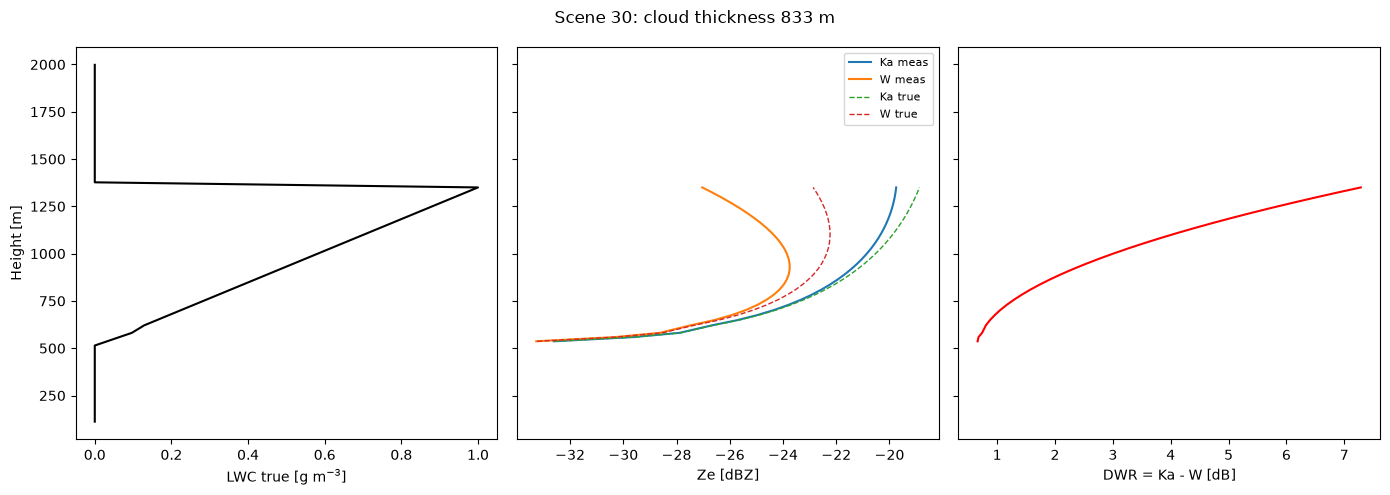

In [15]:
import matplotlib.pyplot as plt

t = 30   # a mid-range thickness case
fig, axes = plt.subplots(1, 3, figsize=(14, 5), sharey=True)

axes[0].plot(ds.LWC_true.isel(Time=t), ds.range, "k-")
axes[0].set_xlabel("LWC true [g m$^{-3}$]"); axes[0].set_ylabel("Height [m]")

axes[1].plot(ds.Ze_Ka.isel(Time=t), ds.range, label="Ka meas")
axes[1].plot(ds.Ze_W.isel(Time=t),  ds.range, label="W meas")
axes[1].plot(ds.Ze_Ka_true.isel(Time=t), ds.range, "--", lw=1, label="Ka true")
axes[1].plot(ds.Ze_W_true.isel(Time=t),  ds.range, "--", lw=1, label="W true")
axes[1].set_xlabel("Ze [dBZ]"); axes[1].legend(fontsize=8)

axes[2].plot(ds.Ze_Ka.isel(Time=t) - ds.Ze_W.isel(Time=t), ds.range, "r-")
axes[2].set_xlabel("DWR = Ka - W [dB]")

fig.suptitle(f"Scene {t}: cloud thickness {float(ds.cloud_thickness[t]):.0f} m")
plt.tight_layout(); plt.show()

In [17]:
ds.attrs = {
    "description": "PAMTRA forward simulation restructured for the Zhu LWC retrieval",
    "source": str(RAW_PATH),
    "note": "Time dimension is cloud thickness, NOT time. Do not average along it.",
    "created_by": "01_load_pamtra.ipynb",
}

out_path = OUT_DIR / "pamtra_aligned.nc"
ds.to_netcdf(out_path)
print("Saved ->", out_path)

Saved -> ..\data\processed\pamtra_test_1\pamtra_aligned.nc


In [18]:
import numpy as np

dz_km = np.gradient(ds_raw["height"].values) / 1000.0
lwc_g = ds_raw["lwc"] * 1000.0                      # kg/m3 -> g/m3

kappa_W_1way = 4.29                                  # dB/km per g/m3, one-way
pred_1way = (kappa_W_1way * lwc_g * xr.DataArray(
    dz_km, dims=["height"], coords={"height": ds_raw.height}))

att_l = ds_raw["att_liquid"].sel(frequency=94.0)
if ATT_IS_CUMULATIVE:
    att_layer = att_l.fillna(0).diff("height")
    pred = pred_1way.isel(height=slice(1, None))
else:
    att_layer, pred = att_l, pred_1way

sel = pred.values > 1e-4
ratio = att_layer.values[sel] / pred.values[sel]
print(f"att_liquid / one-way prediction: median {np.median(ratio):.3f}")
print("  ~1.0 -> PAMTRA is one-way, my 2.0* was right")
print("  ~2.0 -> PAMTRA is already two-way, remove the 2.0*")

att_liquid / one-way prediction: median 1.106
  ~1.0 -> PAMTRA is one-way, my 2.0* was right
  ~2.0 -> PAMTRA is already two-way, remove the 2.0*
